In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset,DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from torchvision import datasets,transforms
from sklearn.metrics import confusion_matrix



In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,),(0.3081))
])

train_dataset=datasets.MNIST(root='./mnist',train=True,download=True,transform=transform)
test_dataset=datasets.MNIST(root='./mnist',train=False,transform=transform)

train_loader=DataLoader(dataset=train_dataset,shuffle=True,batch_size=100)
test_loader=DataLoader(dataset=test_dataset,batch_size=100,shuffle=True)


In [3]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN,self).__init__()
        self.conv1=nn.Conv2d(1,32,kernel_size=3,padding=1)
        self.conv2=nn.Conv2d(32,64,kernel_size=3,padding=1)
        self.pool=nn.MaxPool2d(2,2)
        self.fc1=nn.Linear(64*7*7,128)
        self.fc2=nn.Linear(128,10)

    def forward(self,x):
        x=self.pool(torch.relu(self.conv1(x)))
        x=self.pool(torch.relu(self.conv2(x)))
        x=x.view(-1,64*7*7)
        x=torch.relu(self.fc1(x))
        x=self.fc2(x)
        return x

In [4]:
class RNN(nn.Module):
    def __init__(self,input_size=28,hidden_size=128,num_layers=2,num_classes=10):
        super(RNN,self).__init__()
        self.hidden_size=hidden_size
        self.num_layers=num_layers


        self.lstm=nn.LSTM(input_size,hidden_size,num_layers,batch_first=True)
        self.fc=nn.Linear(hidden_size,num_classes)

    def forward(self,x):
        x=x.squeeze(1)
        h0=torch.zeros(self.num_layers,x.size(0),self.hidden_size).to(device)
        c0=torch.zeros(self.num_layers,x.size(0),self.hidden_size).to(device)

        out,_=self.lstm(x,(h0,c0))
        out=self.fc(out[:,-1,:])
        return out

In [5]:
def train_model(model, num_epochs=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    model.train()
    for epoch in range(num_epochs):
        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Backward and optimize
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

def evaluate_model(model, model_name):
    model.eval()
    all_preds = []
    all_labels = []
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    accuracy = 100 * correct / total
    print(f'Accuracy of {model_name}: {accuracy:.2f}%')
    
    # Generate Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{model_name} Confusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.show()


Training CNN...


Epoch [1/5], Loss: 0.1376


Epoch [2/5], Loss: 0.0458


Epoch [3/5], Loss: 0.0092


Epoch [4/5], Loss: 0.0349


Epoch [5/5], Loss: 0.0064


Accuracy of CNN: 99.02%


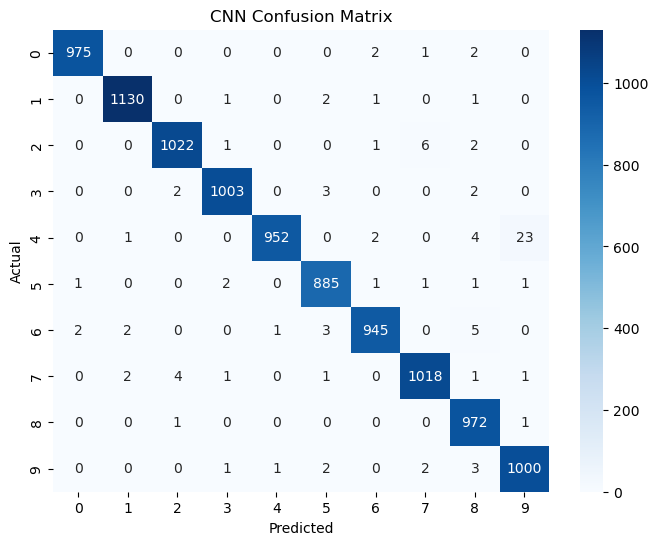


Training RNN...


Epoch [1/5], Loss: 0.1026


Epoch [2/5], Loss: 0.0095


Epoch [3/5], Loss: 0.0689


Epoch [4/5], Loss: 0.0356


Epoch [5/5], Loss: 0.0770


Accuracy of RNN: 98.72%


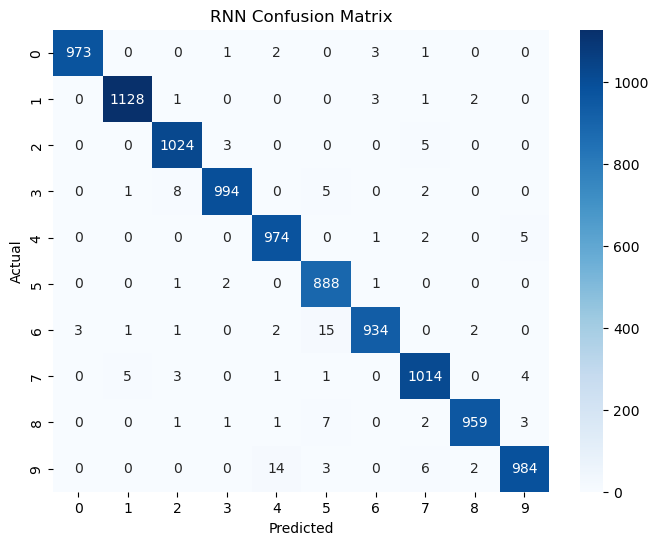

In [6]:
cnn_model=CNN().to(device)
rnn_model=RNN().to(device)

print("Training CNN...")
train_model(cnn_model, num_epochs=5)
evaluate_model(cnn_model, "CNN")

print("\nTraining RNN...")
train_model(rnn_model, num_epochs=5)
evaluate_model(rnn_model, "RNN")
